# Mean Reversion Strategy on Ethereum (ETH)

**Reference:** This project follows [How to create a Mean Reversion strategy (by ex HFT quant trader)](https://youtu.be/_urG139AM48) by MemLabs.
The original notebook used Bitcoin Cash (BCH). I adapted it to Ethereum.

**My goal:** To learn more about mean reversion through a simple hands-on project, using the video above as a reference.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf

In [2]:
ticker = "ETH-USD"
raw = yf.download(ticker, start="2022-04-13", interval="1d",
                  auto_adjust=True, multi_level_index=False,
                  end="2026-11-28")

df = raw.reset_index().rename(columns={
    "Date": "t", "Open": "o", "High": "h", "Low": "l", "Close": "c", "Volume": "v"
})
df

[*********************100%***********************]  1 of 1 completed


,t,c,h,l,o,v
0,2022-04-13,3118.344238,3123.575439,3006.481689,3029.877930,16088473629
1,2022-04-14,3019.909424,3139.928711,2988.435303,3117.821777,15821419931
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281
...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254


### Changes from the original
- Swapped the data source to Ethereum daily prices (ETH-USD) using `yfinance`

## Create Log Returns

In [3]:
df['close_log_return'] = np.log(df['c'] / df['c'].shift())

In [4]:
df

,t,c,h,l,o,v,close_log_return
0,2022-04-13,3118.344238,3123.575439,3006.481689,3029.877930,16088473629,NaN
1,2022-04-14,3019.909424,3139.928711,2988.435303,3117.821777,15821419931,-0.032075
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759
...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792


## Create auto-regressive log returns col

In [5]:
df['close_log_return_lag_1'] = df['close_log_return'].shift()
df = df.dropna().copy()
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222
...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763


## Encode Direction

In [6]:
df['close_log_return_direction_lag_1'] = df['close_log_return_lag_1'].map(lambda x: 1 if x > 0 else -1)
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1
...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1


## Study Price Movements

In [7]:
df.groupby('close_log_return_direction_lag_1').aggregate({'close_log_return':['sum','mean','count']})

close_log_return                
                                              sum      mean count
close_log_return_direction_lag_1                                 
-1                                       0.337565  0.000401   842
 1                                      -0.900979 -0.001065   846

### Out of Sample Validation

In [8]:
i = int(len(df)*0.75)
in_sample, out_sample = df.iloc[:i], df.iloc[i:]

In [9]:
in_sample

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1
...,...,...,...,...,...,...,...,...,...
1263,2025-09-27,4018.658203,4038.451660,3975.758057,4035.914551,20382555776,-0.004278,0.042402,1
1264,2025-09-28,4141.476562,4143.003906,3969.792969,4018.659668,24631307054,0.030104,-0.004278,-1
1265,2025-09-29,4217.341797,4234.782715,4087.927246,4141.356445,38560429932,0.018153,0.030104,1
1266,2025-09-30,4145.957520,4238.671387,4095.443604,4217.055176,37679153330,-0.017071,0.018153,1


In [10]:
out_sample

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1
1268,2025-10-02,4487.923828,4517.665039,4336.526367,4352.240723,48074066058,0.030959,0.048298,1
1269,2025-10-03,4514.870605,4591.443848,4431.479004,4486.934570,49603450230,0.005986,0.030959,1
1270,2025-10-04,4489.197266,4519.526855,4444.012695,4514.909180,21832270764,-0.005703,0.005986,1
1271,2025-10-05,4515.422852,4616.533203,4472.138672,4489.053223,44880806324,0.005825,-0.005703,-1
1272,2025-10-06,4687.771484,4736.208984,4492.870117,4515.300781,44992456374,0.037458,0.005825,1
...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1


In [11]:
in_sample.groupby('close_log_return_direction_lag_1').aggregate({'close_log_return':['sum','mean','count']})

close_log_return                
                                              sum      mean count
close_log_return_direction_lag_1                                 
-1                                       1.066831  0.001691   631
 1                                      -0.701626 -0.001105   635

In [12]:
out_sample.groupby('close_log_return_direction_lag_1').aggregate({'close_log_return':['sum','mean','count']})

close_log_return                
                                              sum      mean count
close_log_return_direction_lag_1                                 
-1                                      -0.729266 -0.003456   211
 1                                      -0.199353 -0.000945   211

### Display Equity Curve

In [13]:
df['signal'] = -1 * df['close_log_return_direction_lag_1']
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1,signal
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1,1
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1,-1
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1,-1
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1,1
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1,-1
...,...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1,-1
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1,1
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1,1
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1,-1


In [14]:
df['trade_log_return'] = df['signal'] * df['close_log_return']
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1,signal,trade_log_return
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1,1,0.006932
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1,-1,-0.007011
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1,-1,0.022759
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1,1,0.021222
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1,-1,-0.015093
...,...,...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1,-1,0.007128
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1,1,-0.018401
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1,1,0.007763
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1,-1,0.001792


In [15]:
df['cum_trade_log_return'] = df['trade_log_return'].cumsum()
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1,signal,trade_log_return,cum_trade_log_return
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1,1,0.006932,0.006932
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1,-1,-0.007011,-0.000079
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1,-1,0.022759,0.022680
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1,1,0.021222,0.043902
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1,-1,-0.015093,0.028808
...,...,...,...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1,-1,0.007128,1.228969
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1,1,-0.018401,1.210568
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1,1,0.007763,1.218331
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1,-1,0.001792,1.220123


<Axes: >

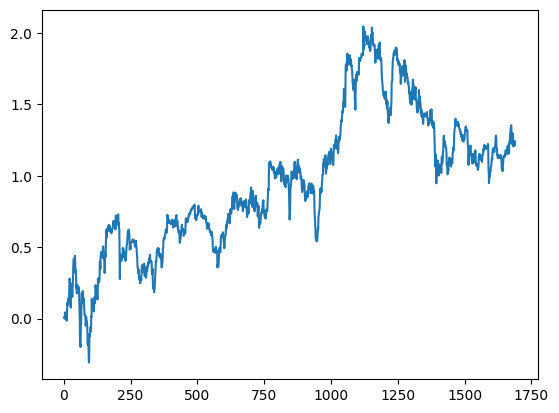

In [16]:
df['cum_trade_log_return'].plot()

## Win Rate

In [17]:
df['is_won'] = df['trade_log_return'] > 0
df

,t,c,h,l,o,v,close_log_return,close_log_return_lag_1,close_log_return_direction_lag_1,signal,trade_log_return,cum_trade_log_return,is_won
2,2022-04-15,3040.916504,3044.287354,3001.123291,3020.134521,11256651536,0.006932,-0.032075,-1,1,0.006932,0.006932,True
3,2022-04-16,3062.310303,3074.886963,3016.421143,3041.123291,8766710365,0.007011,0.006932,1,-1,-0.007011,-0.000079,False
4,2022-04-17,2993.403320,3075.775879,2989.043945,3061.881836,10463091281,-0.022759,0.007011,1,-1,0.022759,0.022680,True
5,2022-04-18,3057.606689,3062.520996,2893.912842,2993.483887,18629381299,0.021222,-0.022759,-1,1,0.021222,0.043902,True
6,2022-04-19,3104.106445,3125.084229,3035.535156,3057.570312,14156035096,0.015093,0.021222,1,-1,-0.015093,0.028808,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1685,2026-11-23,1708.851318,1842.192017,1694.373535,1721.075684,16111424138,-0.007128,0.022844,1,-1,0.007128,1.228969,True
1686,2026-11-24,1677.694824,1719.501099,1662.449951,1708.851318,11272603815,-0.018401,-0.007128,-1,1,-0.018401,1.210568,False
1687,2026-11-25,1690.769043,1696.449219,1607.603882,1677.694824,13491638685,0.007763,-0.018401,-1,1,0.007763,1.218331,True
1688,2026-11-26,1687.741821,1726.693481,1667.661499,1690.769043,7626766254,-0.001792,0.007763,1,-1,0.001792,1.220123,True


In [18]:
df['is_won'].mean()

np.float64(0.5325829383886256)

^ Only win 53 percent of the time

### Total Gross Compound Return

In [19]:
r = np.exp(df['trade_log_return'].sum())-1
r

np.float64(2.450586130014532)

### Annualized Sharpe

In [20]:
df['trade_log_return'].mean()

np.float64(0.0007337346619496229)

In [21]:
df['trade_log_return'].std()

0.03539918349315354

In [22]:
df['trade_log_return'].mean()/df['trade_log_return'].std()

np.float64(0.020727445933647948)

In [23]:
df['trade_log_return'].mean() / df['trade_log_return'].std() * np.sqrt(365)

np.float64(0.39599729853913024)

^annualized sharpe

## Results (gross, before fees)
- Period: Apr 2022 – Nov 2026, ETH-USD daily
- Win rate: 53.2%
- Total gross compound return: +236%
- Annualized Sharpe: 0.39
- In-sample (first 75%): mean reversion pattern is present. After a down day the next day averaged +0.16%; after an up day, −0.11%.
- Out-of-sample (from Oct 2025): the pattern did **not** hold. After down days the next day averaged −0.32%, which was worse than after up days (−0.09%). The strategy lost roughly 38% in this period.

The +236% comes almost entirely from the in-sample period, so it overstates how the strategy would perform today.

## Reflections
This project helped me understand how a simple mean reversion strategy works and made me more familiar with NumPy and pandas. I also learned why log returns are useful. They can simply be added up, which makes it easy to calculate the cumulative trade return and the total gross compound return. The most important lesson was the value of out of sample testing. The pattern looked convincing in sample but did not persist in recent data, so trading it live would have lost money. The out of sample period is also relatively short (~420 days), so neither result is conclusive.